---
# Apresentação:
---

> Este Código foi desenvolvido em Python no Google Colaboratory para a disciplina de MLG.

> **Para um melhor acompanhamento**,
[visualize através do Colab](https://drive.google.com/file/d/1MKftGv0HuQVZF86ILyqznjmWjPLf0-L2/view?usp=sharing) utilizando os índices.


@author: Gustavo Dasa

## SME0823 - Modelos de Regressão e Aprendizado Supervisionado II

### Avaliação 2

#### Entrega até 1/12/2025, individual.

#### Forma de entrega:

O/a aluno/a deve fazer o upload do notebook executado em um repositório github público, indicando seu nome completo e código da disciplina, e indicar link do notebook no e-disciplinas em local que será indicado.

Um estudo clínico busca investigar fatores associados ao número de espirros diários apresentados por indivíduos com rinite alérgica no período em que as plantas mais liberam o pólen no ar. Para cada participante, foram coletadas as seguintes variáveis:

* **nsneeze**: número de espirros observados em um dia (variável resposta de contagem).
* **alcohol**: consumo de bebida alcoólica nas 24 horas anteriores (0 = não, 1 = sim).
* **antihist**: uso de anti-histamínico no dia da observação (0 = não, 1 = sim).
* **smoker**: indicador de tabagismo (0 = não fumante, 1 = fumante).
* **age**: idade do paciente (anos).
* **pollen**: índice quantitativo de concentração de pólen no ar no dia da observação.


**1.** Desenvolva uma breve análise exploratória dos dados e avalie as primeiras impressões sobre a associação entre a variável **nsneeze** e as demais.

**2.** Ajuste um modelo de Poisson para explicar **nsneeze** em função das covariáveis
**alcohol**, **antihist**, **smoker**, **age** e **pollen**. Não é necessário incluir interações.

Apresente e interprete:

* a estimativa dos coeficientes,
* sua significância estatística.

**3.** Verifique se há indícios de superdispersão no modelo de Poisson ajustado no item 2 por, pelo menos, dois métodos diferentes.  

Interprete os resultados e conclua se o modelo de Poisson é adequado em termos de dispersão.


**4.** Caso seja detectada superdispersão, ajuste um modelo **Binomial Negativo** com a mesma estrutura de regressão do item 2. Compare os ajustes de Poisson e Binomial Negativa por meio de:

* desvio (deviance),
* AIC,
* gráficos de resíduos componentes do desvio.

Discuta qual modelo é mais adequado para descrever o número de espirros, justificando sua resposta com base nas métricas e nos diagnósticos gráficos.


**5.** Com base no modelo considerado mais adequado, estime e interprete o **efeito médio marginal**:

* do consumo de álcool (**alcohol**) sobre o número médio de espirros,
* do uso de anti-histamínico (**antihist**).


**6.** Separe os dados em dois subconjuntos, treinamento com 70% das observações e
teste com 30%  das observações. Com base apenas no conjunto de treinamento, ajuste os modelos Poisson e Binomial Negativo com a mesma estrutura de covariáveis dos itens anteriores. No conjunto de teste, calcule, para cada modelo:

* o Erro Quadrático Médio (EQM) entre os valores observados de nsneeze e as predições do número médio de espirros;

* o Erro Absoluto Médio (EAM).

Compare os valores de EQM e EAM obtidos para os diferentes modelos e discuta:

qual deles apresenta melhor desempenho preditivo fora da amostra;

em que medida as conclusões baseadas em critérios de ajuste (deviance, AIC) coincidem ou não com aquelas baseadas nas medidas de desempenho preditivo (EQM e EAM).


**7.** Utilizando o modelo escolhido por você, faça previsões do número **esperado** de espirros para os seguintes perfis:

1. Indivíduo A:

   * alcohol = 0,
   * antihist = 1,
   * smoker = 0,
   * age = 30 anos,
   * pollen = valor correspondente a um dia de baixa concentração.

2. Indivíduo B:

   * alcohol = 1,
   * antihist = 0,
   * smoker = 1,
   * age = 50 anos,
   * pollen = valor correspondente a um dia de alta concentração.


Utilize os códigos abaixo para iniciar suas análises.

Atenção: Se seu número USP

- termina com 0 ou 1, utilize os dados sneeze1
- termina com 2 ou 3, utilize os dados sneeze2
- termina com 4 ou 5, utilize os dados sneeze3
- termina com 6 ou 7, utilize os dados sneeze4
- termina com 8 ou 9, utilize os dados sneeze5

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Datasets/refs/heads/main/sneeze2.csv')
df = df.iloc[:, 1:]
df

,nsneeze,alcohol,antihist,smoker,age,pollen
0,78,0,0,0,32.0,81.085959
1,8,0,0,0,41.0,53.888183
2,34,0,0,1,39.0,92.455084
3,7,0,0,0,56.0,41.246594
4,8,0,0,0,36.0,91.036921
...,...,...,...,...,...,...
1395,10,1,0,0,53.0,57.794915
1396,11,1,0,0,58.0,59.585500
1397,9,0,0,0,36.0,29.955485
1398,18,1,1,0,47.0,63.221483


# Questão 1:

**1.** Desenvolva uma breve análise exploratória dos dados e avalie as primeiras impressões sobre a associação entre a variável **nsneeze** e as demais.


In [2]:
colunas = df.columns
target = 'nsneeze'

features = df.columns.drop(target).to_list()
cat_features = features[:3]
num_features = features[3:]

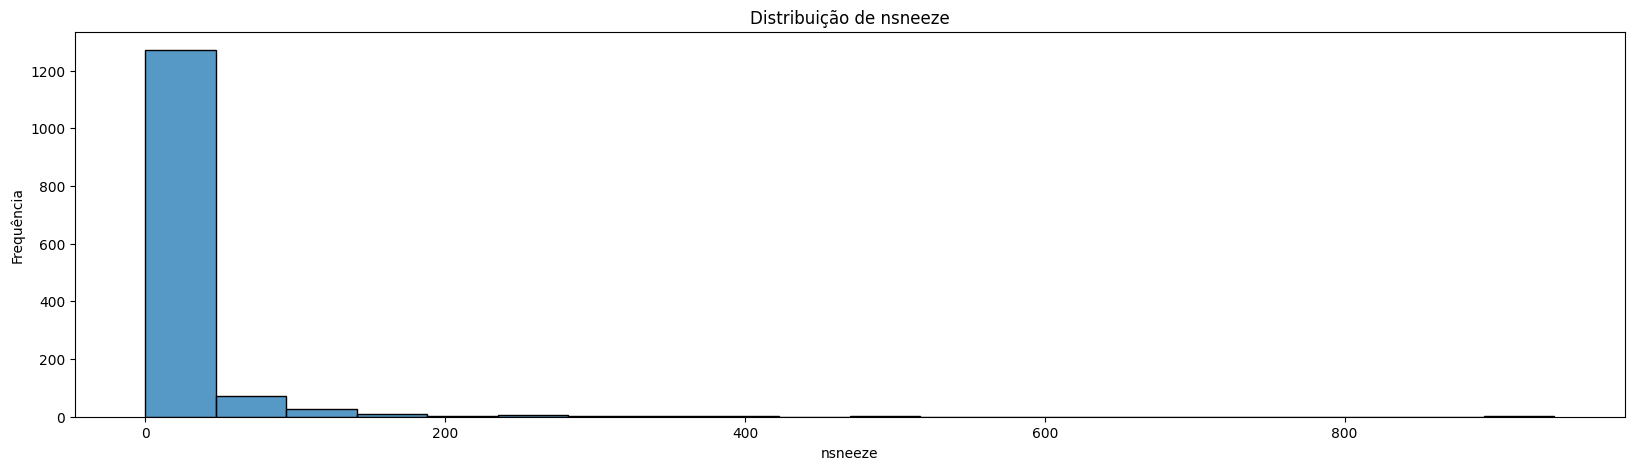

In [3]:
plt.figure(figsize=(20,5))
sns.histplot(df["nsneeze"], kde=False, bins=20)
plt.title("Distribuição de nsneeze")
plt.xlabel("nsneeze")
plt.ylabel("Frequência")
plt.show()

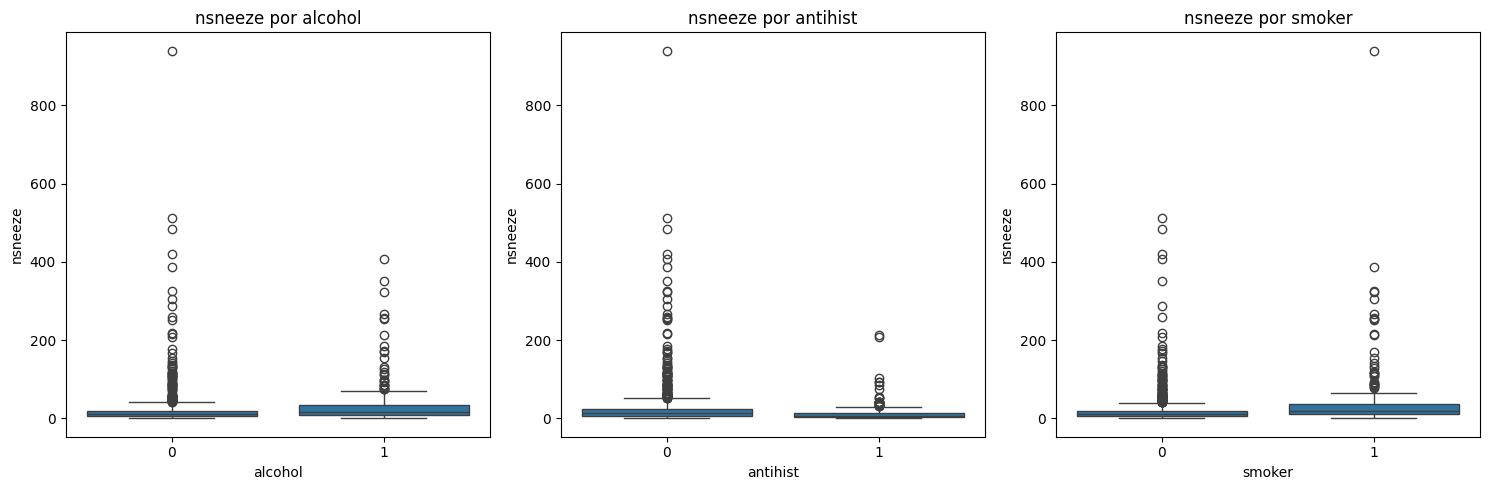

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15,5))

sns.boxplot(x="alcohol", y="nsneeze", data=df, ax=axs[0])
axs[0].set_title("nsneeze por alcohol")

sns.boxplot(x="antihist", y="nsneeze", data=df, ax=axs[1])
axs[1].set_title("nsneeze por antihist")

sns.boxplot(x="smoker", y="nsneeze", data=df, ax=axs[2])
axs[2].set_title("nsneeze por smoker")

plt.tight_layout()
plt.show()

          nsneeze       age    pollen
nsneeze  1.000000 -0.082396  0.601010
age     -0.082396  1.000000 -0.023226
pollen   0.601010 -0.023226  1.000000


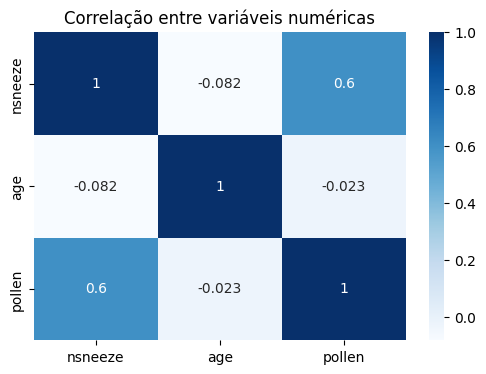

In [5]:
num_vars = ["nsneeze", "age", "pollen"]
corr = df[num_vars].corr()
print(corr)

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("Correlação entre variáveis numéricas")
plt.show()

In [6]:
tab_alcohol = df.groupby("alcohol")["nsneeze"].agg(["mean", "std", "count"])
tab_antihist = df.groupby("antihist")["nsneeze"].agg(["mean", "std", "count"])
tab_smoker  = df.groupby("smoker")["nsneeze"].agg(["mean", "std", "count"])

print("\nMédias por alcohol:\n", tab_alcohol)
print("\nMédias por antihist:\n", tab_antihist)
print("\nMédias por smoker:\n", tab_smoker)


Médias por alcohol:
               mean        std  count
alcohol                             
0        21.253616  49.776434   1037
1        29.628099  47.037683    363

Médias por antihist:
                mean        std  count
antihist                             
0         26.099373  53.609985   1117
1         12.869258  22.261196    283

Médias por smoker:
              mean        std  count
smoker                             
0       19.413274  38.047567   1130
1       40.214815  78.509099    270


In [7]:
mean_ns = df["nsneeze"].mean()
var_ns = df["nsneeze"].var()

print(f"\nMédia de nsneeze: {mean_ns:.3f}")
print(f"Variância de nsneeze: {var_ns:.3f}")

if var_ns > mean_ns * 1.5:
    print("Indício forte de overdispersion.")
else:
    print("Overdispersion não evidente.")


Média de nsneeze: 23.425
Variância de nsneeze: 2420.792
Indício forte de overdispersion.


In [8]:
print("\nDistribuição das covariáveis binárias:")
print(df[["alcohol", "antihist", "smoker"]].apply(pd.Series.value_counts))


Distribuição das covariáveis binárias:
   alcohol  antihist  smoker
0     1037      1117    1130
1      363       283     270


# Questão 2:
**2.** Ajuste um modelo de Poisson para explicar **nsneeze** em função das covariáveis
**alcohol**, **antihist**, **smoker**, **age** e **pollen**. Não é necessário incluir interações.

Apresente e interprete:

* a estimativa dos coeficientes,
* sua significância estatística.


In [9]:
resposta = df['nsneeze']
preditoras = df[['alcohol', 'antihist', 'smoker', 'age', 'pollen']]

In [10]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [11]:
formula = "nsneeze ~ C(alcohol) + C(antihist) + C(smoker) + age + pollen"

modelo_pois = smf.glm(
    formula=formula,
    data=df,
    family=sm.families.Poisson()
)

ajuste_pois = modelo_pois.fit()
print(ajuste_pois.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                nsneeze   No. Observations:                 1400
Model:                            GLM   Df Residuals:                     1394
Model Family:                 Poisson   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -8511.6
Date:                Thu, 27 Nov 2025   Deviance:                       11077.
Time:                        03:06:38   Pearson chi2:                 1.15e+04
No. Iterations:                     5   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            1.5028      0.021  

In [12]:
coef = ajuste_pois.params
irr = np.exp(coef)
pvals = ajuste_pois.pvalues

> alcohol

Coeficiente (β): 0.3221

IRR: 1.3800

Significância: altamente significativo (p < 0.001)

Interpretação: aumenta a taxa de espirros em 38.0% mantendo as demais variáveis constantes.

---
> antihist

Coeficiente (β): -0.5874

IRR: 0.5558

Significância: altamente significativo (p < 0.001)

Interpretação: reduz a taxa de espirros em 44.4% mantendo as demais variáveis constantes.

---
> smoker

Coeficiente (β): 0.6849

IRR: 1.9836

Significância: altamente significativo (p < 0.001)

Interpretação: aumenta a taxa de espirros em 98.4% mantendo as demais variáveis constantes.

---
> age

Coeficiente (β): -0.0122

IRR: 0.9879

Significância: altamente significativo (p < 0.001)

Interpretação: reduz a taxa de espirros em 1.2% mantendo as demais variáveis constantes.

---
> pollen

Coeficiente (β): 0.0260

IRR: 1.0263
Significância: altamente significativo (p < 0.001)

Interpretação: aumenta a taxa de espirros em 2.6% mantendo as demais variáveis constantes.

# Questão 3:
**3.** Verifique se há indícios de superdispersão no modelo de Poisson ajustado no item 2 por, pelo menos, dois métodos diferentes.  

Interprete os resultados e conclua se o modelo de Poisson é adequado em termos de dispersão.


> Já verificamos a superdispersão na variável resposta, o que já indicaria que o modelo Poisson não é adequado.

Seguindo com outros métodos, temos:

In [13]:
pearson = ajuste_pois.pearson_chi2
df_resid = ajuste_pois.df_resid
ratio_pearson = pearson / df_resid

# 3. MÉTODO 1 — Pearson chi² / df
print("\n================ MÉTODO 1 ================")
print(f"Pearson Chi² = {pearson:.2f}")
print(f"df residual = {df_resid}")
print(f"Razão Pearson/df = {ratio_pearson:.3f}")

if ratio_pearson < 1.5:
    print("Interpretação: Não há evidências fortes de superdispersão.")
elif ratio_pearson < 3:
    print("Interpretação: Há indício moderado de superdispersão.")
else:
    print("Interpretação: Superdispersão severa — Poisson não é adequado.")


================ MÉTODO 1 ================
Pearson Chi² = 11489.63
df residual = 1394
Razão Pearson/df = 8.242
Interpretação: Superdispersão severa — Poisson não é adequado.


In [14]:
# MÉTODO 2 — Variância observada / média
mean_y = df["nsneeze"].mean()
var_y  = df["nsneeze"].var()
ratio_var_mean = var_y / mean_y

print("\n================ MÉTODO 2 ================")
print(f"Média(nsneeze) = {mean_y:.3f}")
print(f"Variância(nsneeze) = {var_y:.3f}")
print(f"Razão variância/média = {ratio_var_mean:.3f}")

if ratio_var_mean < 1.5:
    print("Interpretação: Dispersão consistente com Poisson.")
elif ratio_var_mean < 3:
    print("Interpretação: Superdispersão moderada.")
else:
    print("Interpretação: Superdispersão forte — Poisson inadequado.")


================ MÉTODO 2 ================
Média(nsneeze) = 23.425
Variância(nsneeze) = 2420.792
Razão variância/média = 103.342
Interpretação: Superdispersão forte — Poisson inadequado.


In [15]:
def envelope_poisson(fitted_model, X, title):
    resid_dev = fitted_model.resid_deviance.copy()
    sorted_resid = np.sort(resid_dev)

    sim_resid = []
    for _ in range(100):
        mu_sim = np.clip(fitted_model.fittedvalues, 1e-3, 1e5)
        y_sim = np.random.poisson(mu_sim)
        sim_model = sm.GLM(y_sim, X, family=sm.families.Poisson()).fit()
        sim_resid.append(np.sort(sim_model.resid_deviance))

    sim_resid = np.array(sim_resid)
    lower = np.percentile(sim_resid, 2.5, axis=0)
    upper = np.percentile(sim_resid, 97.5, axis=0)

    plt.plot(sorted_resid, '.', label="Resíduos observados", markersize=5,alpha=.7,c='orange')
    plt.plot(lower, 'r--', linewidth=1, label="banda 2.5%")
    plt.plot(upper, 'r--', linewidth=1, label="banda 97.5%")
    plt.title(title)
    plt.xlabel("Ordem dos resíduos")
    plt.ylabel("Resíduo componente do desvio")
    plt.legend()
    plt.grid(True)

Além disso, o envelope dos resíduos do desvio serve para comparar os resíduos observados com o que seria esperado se o modelo estivesse bem ajustado.
Como os resíduos estão muito mais espalhados do que o envelope simulado e vários pontos fora do envelope, temos outra indicação de superdispersão clara e má adequação do Poisson.

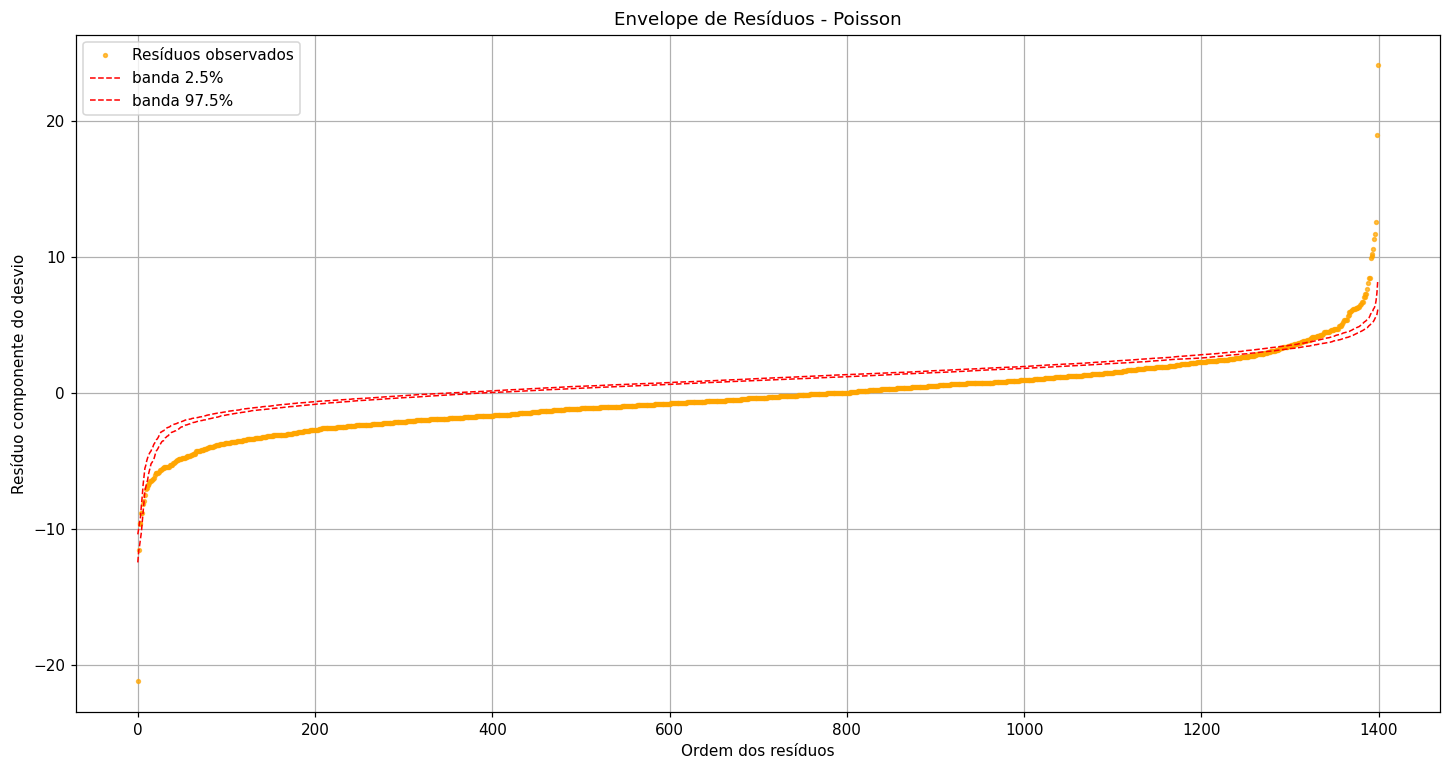

In [16]:
results = ajuste_pois
X = preditoras
plt.figure(figsize=(16, 8), dpi=110)
envelope_poisson(results, X, "Envelope de Resíduos - Poisson")

In [17]:
print("\n================ CONCLUSÃO FINAL ================")
if ratio_pearson > 3 or ratio_var_mean > 3:
    print("Resultado: O modelo Poisson apresenta superdispersão severa. Use Binomial Negativa.")
else:
    print("Resultado: O modelo Poisson é aceitável em termos de dispersão.")


================ CONCLUSÃO FINAL ================
Resultado: O modelo Poisson apresenta superdispersão severa. Use Binomial Negativa.


# Questão 4:
**4.** Caso seja detectada superdispersão, ajuste um modelo **Binomial Negativo** com a mesma estrutura de regressão do item 2. Compare os ajustes de Poisson e Binomial Negativa por meio de:

* desvio (deviance),
* AIC,
* gráficos de resíduos componentes do desvio.

Discuta qual modelo é mais adequado para descrever o número de espirros, justificando sua resposta com base nas métricas e nos diagnósticos gráficos.


In [18]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

formula = "nsneeze ~ C(alcohol) + C(antihist) + C(smoker) + age + pollen"

alpha_fixado = 0.2

#alpha para sneeze1 a sneeze5 = 0.23, 0.3, 0.25,  0.2, 0.2

modelo_nb = smf.glm(
    formula=formula,
    data=df,
    family=sm.families.NegativeBinomial(alpha=alpha_fixado)
)

ajuste_nb = modelo_nb.fit()
print(ajuste_nb.summary())

alpha_usado = ajuste_nb.family.alpha
print("Alpha usado no modelo:", alpha_usado)

alpha_est = ajuste_nb.params.iloc[-1]
print("Alpha estimado:", alpha_est)


                 Generalized Linear Model Regression Results                  
Dep. Variable:                nsneeze   No. Observations:                 1400
Model:                            GLM   Df Residuals:                     1394
Model Family:        NegativeBinomial   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -4937.3
Date:                Thu, 27 Nov 2025   Deviance:                       2066.5
Time:                        03:06:41   Pearson chi2:                 1.91e+03
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9831
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            1.5228      0.055  

In [19]:
alpha_est = ajuste_nb.params.iloc[-1]
print("Alpha estimado:", alpha_est)

Alpha estimado: 0.025361740166470463


In [20]:
print("\n=== COMPARAÇÃO DE PERFORMANCE ===")
print(f"Deviance Poisson:          {ajuste_pois.deviance:.2f}")
print(f"Deviance NegBin:           {ajuste_nb.deviance:.2f}")
print(f"AIC Poisson:               {ajuste_pois.aic:.2f}")
print(f"AIC NegBin:                {ajuste_nb.aic:.2f}")


=== COMPARAÇÃO DE PERFORMANCE ===
Deviance Poisson:          11077.48
Deviance NegBin:           2066.52
AIC Poisson:               17035.13
AIC NegBin:                9886.66


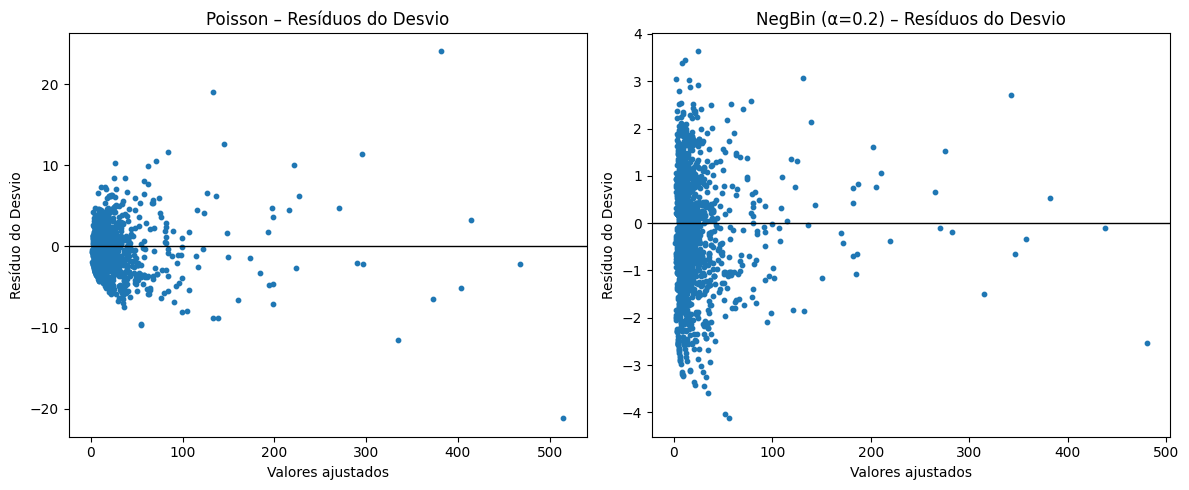

In [21]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(ajuste_pois.fittedvalues, ajuste_pois.resid_deviance, s=10)
plt.axhline(0, color='black', lw=1)
plt.title("Poisson – Resíduos do Desvio")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduo do Desvio")

plt.subplot(1,2,2)
plt.scatter(ajuste_nb.fittedvalues, ajuste_nb.resid_deviance, s=10)
plt.axhline(0, color='black', lw=1)
plt.title("NegBin (α=0.2) – Resíduos do Desvio")
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduo do Desvio")

plt.tight_layout()
plt.show()

In [22]:
def envelope_negbin(fitted_model, title):
    # resíduos observados
    resid_dev = fitted_model.resid_deviance.copy()
    sorted_resid = np.sort(resid_dev)

    # matriz de design e parâmetros do próprio modelo
    X = fitted_model.model.exog
    mu = np.clip(fitted_model.fittedvalues, 1e-3, 1e5)
    alpha = fitted_model.family.alpha

    sim_resid = []
    for _ in range(100):
        # simula Y ~ NB(mu, alpha) com a mesma parametrização
        n_sim = 1 / alpha
        p_sim = n_sim / (n_sim + mu)
        y_sim = np.random.negative_binomial(n=n_sim, p=p_sim)

        sim_model = sm.GLM(
            y_sim,
            X,
            family=sm.families.NegativeBinomial(alpha=alpha)
        ).fit()

        sim_resid.append(np.sort(sim_model.resid_deviance))

    sim_resid = np.array(sim_resid)
    lower = np.percentile(sim_resid, 2.5, axis=0)
    upper = np.percentile(sim_resid, 97.5, axis=0)

    plt.plot(sorted_resid, ".", label="Resíduos observados", markersize=5,alpha=.7,c='orange')
    plt.plot(lower, "r--", linewidth=1, label="banda 2.5%")
    plt.plot(upper, "r--", linewidth=1, label="banda 97.5%")
    plt.title(title)
    plt.xlabel("Ordem dos resíduos")
    plt.ylabel("Resíduo componente do desvio")
    plt.legend()
    plt.grid(True)


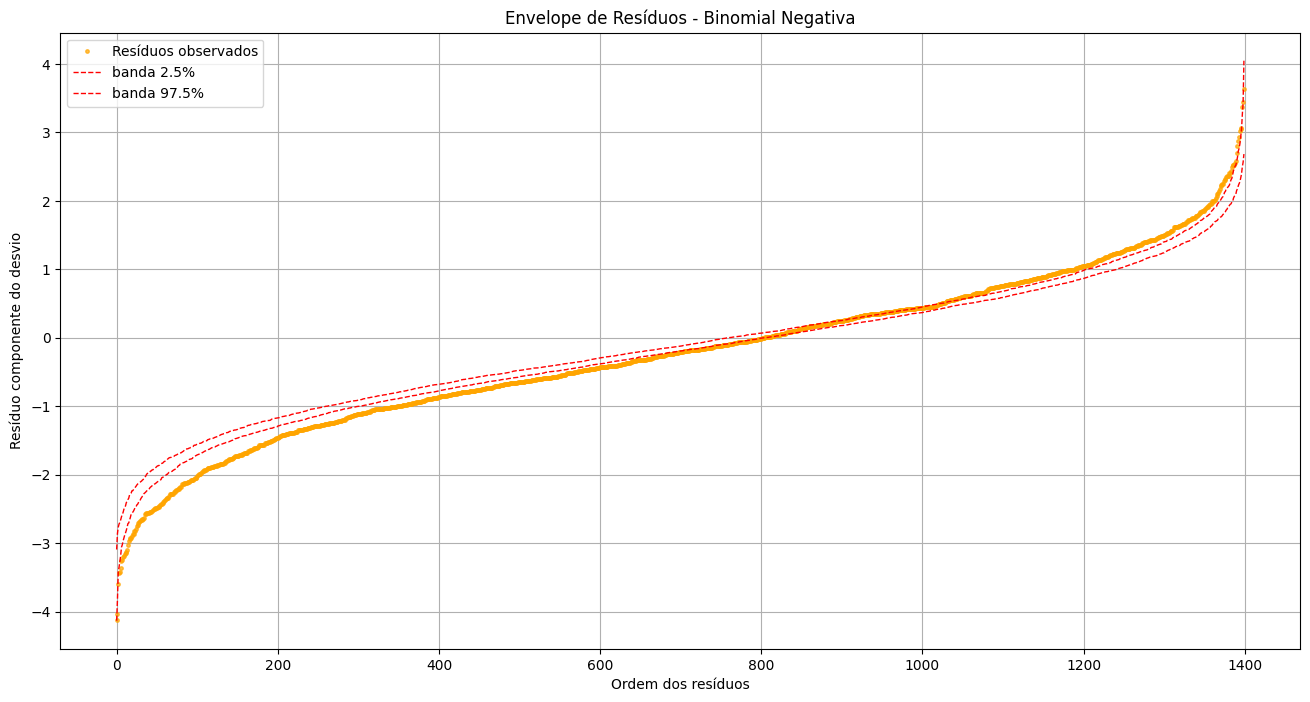

In [23]:
results_nb = ajuste_nb

plt.figure(figsize=(16, 8), dpi=100)
envelope_negbin(results_nb, "Envelope de Resíduos - Binomial Negativa")

In [24]:
print("\n=== CONCLUSÃO ===")

if ajuste_nb.deviance < ajuste_pois.deviance and ajuste_nb.aic < ajuste_pois.aic:
    print("A Binomial Negativa apresenta ajuste MUITO melhor (menor deviance e AIC).")
    print("O modelo Poisson sofre superdispersão e não é adequado.")
else:
    print("Não há melhora clara da Negative Binomial sobre o Poisson.")


=== CONCLUSÃO ===
A Binomial Negativa apresenta ajuste MUITO melhor (menor deviance e AIC).
O modelo Poisson sofre superdispersão e não é adequado.


# Questão 5:

**5.** Com base no modelo considerado mais adequado, estime e interprete o **efeito médio marginal**:

* do consumo de álcool (**alcohol**) sobre o número médio de espirros,
* do uso de anti-histamínico (**antihist**).


In [25]:
def ame_discrete_change(model, data, varname):
    # cópia dos dados
    d0 = data.copy()
    d1 = data.copy()
    # forçar 0 e 1
    d0[varname] = 0
    d1[varname] = 1
    # predizer médias (μ) para cada observação
    mu0 = model.predict(d0)  # μ quando var = 0
    mu1 = model.predict(d1)  # μ quando var = 1
    # diferenças individuais
    diff = mu1 - mu0
    rel = np.where(mu0 == 0, np.nan, (mu1 - mu0) / mu0)  # percentual (NaN se mu0==0)
    # estatísticas
    n = len(diff)
    ame_abs = np.nanmean(diff)
    ame_rel = np.nanmean(rel)  # média dos percentuais (ignora NaNs)
    # erro padrão aproximado (baseado na variabilidade amostral das diferenças)
    se_abs = np.nanstd(diff, ddof=1) / np.sqrt(np.sum(~np.isnan(diff)))
    se_rel = np.nanstd(rel[~np.isnan(rel)], ddof=1) / np.sqrt(np.sum(~np.isnan(rel)))
    # 95% CI aproximado
    ci_abs = (ame_abs - 1.96*se_abs, ame_abs + 1.96*se_abs)
    ci_rel = (ame_rel - 1.96*se_rel, ame_rel + 1.96*se_rel)
    return {
        "var": varname,
        "n": n,
        "ame_abs": ame_abs,
        "se_abs": se_abs,
        "ci_abs": ci_abs,
        "ame_rel": ame_rel,
        "se_rel": se_rel,
        "ci_rel": ci_rel,
        "mu0_mean": np.nanmean(mu0),
        "mu1_mean": np.nanmean(mu1)
    }

res_alcohol = ame_discrete_change(ajuste_nb, df, "alcohol")
res_antihist = ame_discrete_change(ajuste_nb, df, "antihist")

In [26]:
def print_ame(res):
    print(f"\n--- Efeito médio marginal para {res['var']} (0 -> 1) ---")
    print(f"N (obs): {res['n']}")
    print(f"Efeito médio absoluto (Δ espirros/dia): {res['ame_abs']:.4f}")
    print(f"IC 95% (aprox.) do efeito absoluto: ({res['ci_abs'][0]:.4f}, {res['ci_abs'][1]:.4f})")
    print(f"Efeito médio relativo (média do % mudança): {res['ame_rel']*100:.2f}%")
    print(f"IC 95% (aprox.) relativo: ({res['ci_rel'][0]*100:.2f}%, {res['ci_rel'][1]*100:.2f}%)")
    print(f"Média(μ|var=0): {res['mu0_mean']:.4f}, Média(μ|var=1): {res['mu1_mean']:.4f}")

print_ame(res_alcohol)
print_ame(res_antihist)


--- Efeito médio marginal para alcohol (0 -> 1) ---
N (obs): 1400
Efeito médio absoluto (Δ espirros/dia): 8.6789
IC 95% (aprox.) do efeito absoluto: (7.8990, 9.4589)
Efeito médio relativo (média do % mudança): 41.85%
IC 95% (aprox.) relativo: (41.85%, 41.85%)
Média(μ|var=0): 20.7393, Média(μ|var=1): 29.4182

--- Efeito médio marginal para antihist (0 -> 1) ---
N (obs): 1400
Efeito médio absoluto (Δ espirros/dia): -11.4256
IC 95% (aprox.) do efeito absoluto: (-12.3671, -10.4841)
Efeito médio relativo (média do % mudança): -45.49%
IC 95% (aprox.) relativo: (-45.49%, -45.49%)
Média(μ|var=0): 25.1178, Média(μ|var=1): 13.6922


# Questão 7:
**7.** Utilizando o modelo escolhido por você, faça previsões do número **esperado** de espirros para os seguintes perfis:

1. Indivíduo A:

   * alcohol = 0,
   * antihist = 1,
   * smoker = 0,
   * age = 30 anos,
   * pollen = valor correspondente a um dia de baixa concentração.

2. Indivíduo B:

   * alcohol = 1,
   * antihist = 0,
   * smoker = 1,
   * age = 50 anos,
   * pollen = valor correspondente a um dia de alta concentração.

In [27]:
ajuste_nb.predict(pd.DataFrame([[0,1,0,30,10],
                [1,0,1,50,100]], columns=features))

,0
0,2.298013
1,87.598342


> 1) Caso 1: [0,1,0,30,10] → 2.30 espirros

Sem álcool, com anti-histamínico, não fumante de 30 anos
pólen = 10 (baixo)

Interpretação:
O modelo prevê poucos espirros, consistente com uso de anti-histamínico (efeito protetor) e baixa concentração de pólen.


---
> 2) Caso 2: [1,0,1,50,100] → 87.60 espirros

Consumiu álcool, não tomou anti-histamínico, fumante de 50 anos
pólen = 100 (muito alto)

Interpretação:
O modelo prevê fortíssima exacerbação de sintomas.
Isso acontece porque:
- álcool aumenta espirros
- fumo aumenta espirros
- ausência de anti-histamínico aumenta espirros

pólen extremamente alto (100) eleva exponencialmente a predição.